# Project Task 1 — Preprocessing (hourly)

**Station HY024** (Etobicoke Creek), warm season (April–November), study years 2013–2020.

> **Update (hourly rebuild).** This notebook previously aggregated to **daily mean** discharge.
> Per project guidance, all downstream modeling is now done on **hourly mean discharge**, so this
> notebook resamples the 15-minute record to hourly, engineers hour-scale features (not day-scale),
> and adds a diurnal (hour-of-day) cyclic encoding alongside the existing seasonal (day-of-year) one.
> It also fixes two correctness issues found in the daily version:
> 1. A stray literal newline inside a `print('\n...')` call that raised a `SyntaxError`.
> 2. Lags/rolling windows were computed as a plain row-shift over the *concatenated* warm-season
>    calendar, so the first rows of April silently pulled "lag" values from the previous
>    November (a ~4-month jump). Every lag/rolling feature below is now computed **per
>    warm-season year** (`groupby(year)`), so no feature window ever straddles the off-season gap —
>    the same principle the [TensorFlow time series tutorial](https://www.tensorflow.org/tutorials/structured_data/time_series)
>    uses when it windows a single contiguous series, adapted here for 8 independent
>    seasonal "runs" instead of one continuous record.


### Step 1 — Setup

In [1]:
import os, sys
from pathlib import Path

def detect_platform() -> str:
    if 'google.colab' in sys.modules or 'COLAB_GPU' in os.environ:
        return 'colab'
    if os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
        return 'kaggle'
    return 'local'

PLATFORM = detect_platform()
if PLATFORM == 'colab':
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/ITEC 4000')
    print('Colab: cwd set to', os.getcwd())
else:
    print('Platform:', PLATFORM, '— assuming Jupyter was started inside the repo (or a parent of it).')


Platform: local — assuming Jupyter was started inside the repo (or a parent of it).


In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / 'README.md').exists() and (candidate / 'data').is_dir():
        PROJECT_ROOT = candidate
        break
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from hydro_course.paths import DATA_PROCESSED, ensure_module_dirs
paths = ensure_module_dirs('module_03')

DATA_FILE = DATA_PROCESSED / 'dis024_processed.csv'
print('Project root:', PROJECT_ROOT)
print('Anchor file exists:', DATA_FILE.exists())


Project root: /private/tmp/exec_root
Anchor file exists: True


### Step 2 — Load 15-minute data and inspect

In [3]:
raw = pd.read_csv(DATA_FILE, parse_dates=['Time_Tag']).sort_values('Time_Tag').reset_index(drop=True)
print('Rows :', f'{len(raw):,}')
print('Range:', raw['Time_Tag'].min(), '\u2192', raw['Time_Tag'].max())
print('Columns:', list(raw.columns))
print(raw.head(3))

dt = raw['Time_Tag'].diff().dt.total_seconds().dropna()
print('\nMedian sampling interval (s):', int(dt.median()))
print('Distinct intervals (top 5)   :', dt.value_counts().head().to_dict())


Rows : 287,204
Range: 2012-11-20 13:00:00 → 2021-02-03 12:30:00
Columns: ['StationID', 'Time_Tag', 'Parameter', 'MeasuredValue']
  StationID            Time_Tag  Parameter  MeasuredValue
0     HY024 2012-11-20 13:00:00  Discharge       0.171658
1     HY024 2012-11-20 13:15:00  Discharge       0.171658
2     HY024 2012-11-20 13:30:00  Discharge       0.171658



Median sampling interval (s): 900
Distinct intervals (top 5)   : {900.0: 287175, 1800.0: 4, 4500.0: 4, 2700.0: 3, 12600.0: 2}


### Step 3 — Resample to hourly mean

We aggregate to **hourly mean Q** (not daily) because the models in Modules 4–5 are now trained
and evaluated at hourly resolution — daily averaging would throw away the diurnal signal and most
of the storm rise/recession shape. `q_max` / `q_min` per hour are kept for the physical-outlier
check below.

We restrict to the **warm season** (April 1 – November 30) and to the 8 calendar years with a
**complete** warm season on record, 2013–2020 (2012 and 2021 only have partial seasons).


Hourly rows (Apr–Nov, 2013-2020): 46848


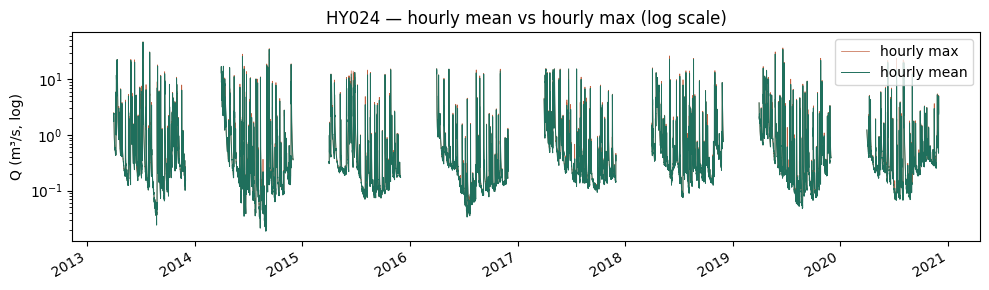

In [4]:
WARM_MONTHS = list(range(4, 12))      # April(4) ... November(11)
STUDY_YEARS = list(range(2013, 2021))  # 8 complete warm seasons
MAX_GAP_HOURS = 48                      # short-gap interpolation threshold (~2 days)

hourly_mean = (raw.set_index('Time_Tag')['MeasuredValue']
                  .resample('h').mean()
                  .rename('q_mean'))
hourly_max  = (raw.set_index('Time_Tag')['MeasuredValue']
                  .resample('h').max()
                  .rename('q_max'))
hourly_min  = (raw.set_index('Time_Tag')['MeasuredValue']
                  .resample('h').min()
                  .rename('q_min'))
hourly = pd.concat([hourly_mean, hourly_max, hourly_min], axis=1)

hourly = hourly[hourly.index.month.isin(WARM_MONTHS) & hourly.index.year.isin(STUDY_YEARS)].copy()
print('Hourly rows (Apr\u2013Nov, 2013-2020):', len(hourly))

# Plotted one warm-season year at a time (not as one concatenated line) so matplotlib never
# draws a spurious connecting line across the ~4-month off-season gap between years.
fig, ax = plt.subplots(figsize=(10, 3))
for i, y in enumerate(STUDY_YEARS):
    sub = hourly[hourly.index.year == y]
    ax.plot(sub.index, sub['q_max'],  color='#c2603f', lw=0.5, label='hourly max' if i == 0 else None)
    ax.plot(sub.index, sub['q_mean'], color='#1f6f5c', lw=0.7, label='hourly mean' if i == 0 else None)
ax.set_yscale('log'); ax.set_ylabel('Q (m\u00b3/s, log)')
ax.legend(); ax.set_title('HY024 \u2014 hourly mean vs hourly max (log scale)')
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(paths['figures'] / 'm3_hourly_overview.png', dpi=150, bbox_inches='tight')
plt.show()


### Step 4 — Per-year hourly calendar, gaps, and short-gap interpolation

Each warm-season year is treated as an **independent run**: we build a *complete* hourly calendar
for that year only (April 1 00:00 \u2192 November 30 23:00), reindex onto it to expose missing hours,
and interpolate gaps of \u2264 48 hours (2 days) *within that year*. Gaps longer than 48 hours are left
as `NaN` and dropped later — they are rare enough (see table below) that we do not need the more
elaborate run-splitting logic the daily version used.

Doing this per year (instead of concatenating all years into one calendar) guarantees interpolation
never bridges the ~4-month off-season gap between November 30 of one year and April 1 of the next.


In [5]:
def year_warm_calendar(year: int) -> pd.DatetimeIndex:
    start = pd.Timestamp(year=year, month=4, day=1, hour=0)
    end   = pd.Timestamp(year=year, month=11, day=30, hour=23)
    return pd.date_range(start, end, freq='h')

def short_gap_interpolate(series: pd.Series, max_gap: int = 48) -> pd.Series:
    """Linearly interpolate (time-aware) runs of NaN of length <= max_gap; longer runs stay NaN."""
    s = series.copy()
    is_na = s.isna()
    gid = (is_na != is_na.shift()).cumsum()
    sizes = is_na.groupby(gid).transform('sum')
    fillable = is_na & (sizes <= max_gap)
    interp = s.interpolate(method='time')
    s.loc[fillable] = interp.loc[fillable]
    return s

frames, report_rows = [], []
for y in STUDY_YEARS:
    idx = year_warm_calendar(y)
    sub = hourly.reindex(idx).copy()
    n_missing_before = int(sub['q_mean'].isna().sum())
    sub['q_mean'] = short_gap_interpolate(sub['q_mean'], max_gap=MAX_GAP_HOURS)
    n_missing_after = int(sub['q_mean'].isna().sum())
    report_rows.append(dict(year=y, hours=len(idx),
                             missing_before=n_missing_before,
                             missing_after=n_missing_after,
                             pct_missing_before=round(100 * n_missing_before / len(idx), 3)))
    frames.append(sub)

hourly_full = pd.concat(frames)
gap_report = pd.DataFrame(report_rows)
print(gap_report.to_string(index=False))
print('\nTotal hourly slots :', len(hourly_full))
print('Remaining NaN after short-gap fill:', int(hourly_full['q_mean'].isna().sum()))


 year  hours  missing_before  missing_after  pct_missing_before
 2013   5856               8              0               0.137
 2014   5856               0              0               0.000
 2015   5856              14              0               0.239
 2016   5856               4              1               0.068
 2017   5856              41              0               0.700
 2018   5856               0              0               0.000
 2019   5856               0              0               0.000
 2020   5856               0              0               0.000

Total hourly slots : 46848
Remaining NaN after short-gap fill: 1


### Step 5 — Outliers — physical and statistical

A **physical bound** (Q can never be negative, or exceed a generous multiple of the historic max)
and a **trailing rolling-z** check (an hour far outside its own 14-day, *within-year* local mean).
The rolling window is computed **per warm-season year** for the same reason as the gap fill —
otherwise the first 14 days of every April would compare themselves against late-November values
from the year before.


In [6]:
q = hourly_full['q_mean'].copy()

def per_year_trailing_stat(s: pd.Series, window: int, stat: str, min_periods: int) -> pd.Series:
    """Trailing (shift-1) rolling statistic, computed independently within each calendar year."""
    def _roll(x):
        r = x.shift(1).rolling(window, min_periods=min_periods)
        return getattr(r, stat)()
    return s.groupby(s.index.year, group_keys=False).apply(_roll)

ROLL_Z_WINDOW, ROLL_Z_MIN = 24 * 14, 24 * 7   # 14-day trailing window, needs >= 7 days of history

roll_mean = per_year_trailing_stat(q, ROLL_Z_WINDOW, 'mean', ROLL_Z_MIN)
roll_std  = per_year_trailing_stat(q, ROLL_Z_WINDOW, 'std',  ROLL_Z_MIN)
zscore    = (q - roll_mean) / roll_std
extreme   = zscore.abs() > 4

phys_min, phys_max = 0.0, 5 * float(hourly_full['q_max'].max())
phys_violations = ((q < phys_min) | (q > phys_max)).sum()

print('Physical-bound violations  :', int(phys_violations))
print('|z| > 4 candidate outliers :', int(extreme.sum()), 'of', len(q), 'hours')

suspect = pd.DataFrame({'q': q, 'roll_mean': roll_mean, 'z': zscore}).loc[extreme.fillna(False)]
print(suspect.sort_values('z', ascending=False).head(8).round(3))


Physical-bound violations  : 0
|z| > 4 candidate outliers : 977 of 46848 hours
                          q  roll_mean       z
2015-05-30 15:00:00   1.761      0.223  75.834
2017-07-20 11:00:00   2.988      0.176  74.109
2017-07-20 13:00:00  11.709      0.191  57.148
2014-09-02 15:00:00  11.229      0.073  56.693
2020-07-10 22:00:00  12.314      0.150  54.713
2016-08-13 16:00:00  13.073      0.121  53.224
2016-05-13 02:00:00  15.281      0.432  52.101
2018-05-31 21:00:00  13.482      0.368  50.222


On hydrographs, large |z| values are usually *real floods*, not errors — so we flag, not drop.

In [7]:
outlier_flag = (extreme | (q < phys_min) | (q > phys_max)).fillna(False)
print('Outliers flagged (kept in data):', int(outlier_flag.sum()))


Outliers flagged (kept in data): 977


### Step 6 — Engineer hourly features

Lags and rolling statistics are now on an **hour** scale, and — like the gap fill and the outlier
check — computed **per warm-season year** so no feature ever looks across the off-season gap:

- `q_lag1/2/3` — the last few hours (short-memory / persistence signal)
- `q_lag24` — the same hour **yesterday** (captures the diurnal cycle)
- `q_lag168` — the same hour **last week**
- `q_roll24_*` — trailing 24-hour (past day) mean / std / max
- `q_roll168_*` — trailing 168-hour (past week) mean / max
- `q_roll720_*` — trailing 720-hour (~30-day) mean / max (baseflow / recession signal)
- `sin_hour` / `cos_hour` — cyclic encoding of **hour-of-day** (new — matters at hourly resolution)
- `sin_doy` / `cos_doy` — cyclic encoding of day-of-year (seasonal signal, kept from the daily version)

The sin/cos-of-clock-time encodings mirror the "Time" signal engineering step in the
[TensorFlow time series tutorial](https://www.tensorflow.org/tutorials/structured_data/time_series#time)
(they encode day-of-year and time-of-day as sin/cos pairs so the model sees the clock as continuous,
not as an integer that jumps from 23 back to 0, or 365 back to 1).


In [8]:
LAGS = (1, 2, 3, 24, 168)
ROLLS = [(24, 'mean'), (24, 'std'), (24, 'max'), (168, 'mean'), (168, 'max'), (720, 'mean'), (720, 'max')]

def per_year_shift(s: pd.Series, lag: int) -> pd.Series:
    return s.groupby(s.index.year).shift(lag)

features = pd.DataFrame(index=q.index)
features['q'] = q
for lag in LAGS:
    features[f'q_lag{lag}'] = per_year_shift(q, lag)
for window, stat in ROLLS:
    min_periods = max(2, window // 2)
    features[f'q_roll{window}_{stat}'] = per_year_trailing_stat(q, window, stat, min_periods)
features['outlier_flag'] = outlier_flag.astype(int)

hour = features.index.hour.values
features['sin_hour'] = np.sin(2 * np.pi * hour / 24)
features['cos_hour'] = np.cos(2 * np.pi * hour / 24)

doy = features.index.dayofyear.values
features['sin_doy'] = np.sin(2 * np.pi * doy / 365.25)
features['cos_doy'] = np.cos(2 * np.pi * doy / 365.25)
features['month'] = features.index.month
features['year']  = features.index.year

print(features.tail(3).round(3))


                         q  q_lag1  q_lag2  q_lag3  q_lag24  q_lag168  \
2020-11-30 21:00:00  3.207   3.638   4.338   4.965    0.497     0.911   
2020-11-30 22:00:00  2.852   3.207   3.638   4.338    0.499     0.887   
2020-11-30 23:00:00  2.384   2.852   3.207   3.638    0.500     0.852   

                     q_roll24_mean  q_roll24_std  q_roll24_max  \
2020-11-30 21:00:00          1.498         1.617         5.009   
2020-11-30 22:00:00          1.611         1.639         5.009   
2020-11-30 23:00:00          1.709         1.640         5.009   

                     q_roll168_mean  q_roll168_max  q_roll720_mean  \
2020-11-30 21:00:00           1.152          5.293           0.592   
2020-11-30 22:00:00           1.165          5.293           0.596   
2020-11-30 23:00:00           1.177          5.293           0.600   

                     q_roll720_max  outlier_flag  sin_hour  cos_hour  sin_doy  \
2020-11-30 21:00:00          5.293             0    -0.707     0.707   -0.497   

### Step 7 — Seasonality and autocorrelation diagnostics

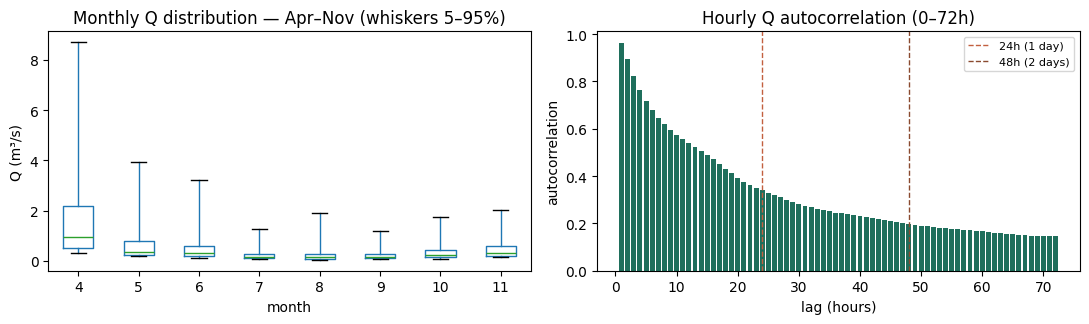

First three autocorrelations (lags 1-3h): [0.964 0.895 0.824]


In [9]:
monthly = features.dropna(subset=['q']).copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
monthly.boxplot(column='q', by='month', ax=axes[0], grid=False, whis=(5, 95), showfliers=False)
axes[0].set_title('Monthly Q distribution \u2014 Apr\u2013Nov (whiskers 5\u201395%)')
axes[0].set_xlabel('month'); axes[0].set_ylabel('Q (m\u00b3/s)')
plt.suptitle('')

# Hourly autocorrelation out to 3 days — short lags show persistence, ~24h/48h mark the diurnal cycle
sub = features['q'].dropna()
lags = np.arange(1, 73)
acf = np.array([sub.autocorr(lag=k) for k in lags])
axes[1].bar(lags, acf, color='#1f6f5c')
axes[1].axvline(24, color='#c2603f', lw=1, ls='--', label='24h (1 day)')
axes[1].axvline(48, color='#8a4a2f', lw=1, ls='--', label='48h (2 days)')
axes[1].axhline(0, color='black', lw=0.7)
axes[1].set_xlabel('lag (hours)'); axes[1].set_ylabel('autocorrelation')
axes[1].set_title('Hourly Q autocorrelation (0\u201372h)'); axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(paths['figures'] / 'm3_seasonality_and_acf.png', dpi=150, bbox_inches='tight')
plt.show()
print('First three autocorrelations (lags 1-3h):', acf[:3].round(3))


### Step 8 — Drop feature warm-up rows and inspect per-year coverage

The 720-hour rolling features need ~30 days of history, so the **first ~30 days of every warm
season** are dropped after computing features (this is the trailing-feature warm-up cost of
`q_roll720_*`, paid once per independent year-run). No fixed train/val/test split is baked in here —
Modules 4 and 5 evaluate each model with **leave-one-year-out cross-validation** across the 8 study
years instead of a single chronological split, so this notebook just exports the full cleaned
per-year table with a `year` column.


In [10]:
feature_cols_for_dropna = [c for c in features.columns
                           if c not in ('outlier_flag', 'sin_hour', 'cos_hour', 'sin_doy', 'cos_doy', 'month', 'year')]
clean = features.dropna(subset=feature_cols_for_dropna).copy()
print('Rows before dropna:', len(features), '| after:', len(clean))
print('\nRows per study year:')
print(clean.groupby('year').size())


Rows before dropna: 46848 | after: 43967

Rows per study year:
year
2013    5496
2014    5496
2015    5496
2016    5495
2017    5496
2018    5496
2019    5496
2020    5496
dtype: int64


### Step 9 — Visualise all 8 years + flagged outliers

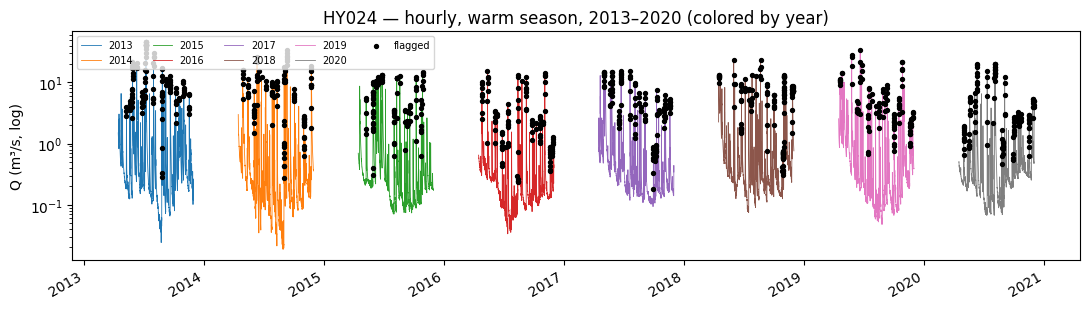

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.2))
cmap = plt.get_cmap('tab10')
for i, y in enumerate(STUDY_YEARS):
    sub = clean[clean['year'] == y]
    ax.plot(sub.index, sub['q'], color=cmap(i % 10), lw=0.6, label=str(y))
flag_idx = clean.index[clean['outlier_flag'] == 1]
ax.scatter(flag_idx, clean.loc[flag_idx, 'q'], s=8, color='black', label='flagged', zorder=3)
ax.set_yscale('log'); ax.set_ylabel('Q (m\u00b3/s, log)')
ax.set_title('HY024 \u2014 hourly, warm season, 2013\u20132020 (colored by year)')
ax.legend(ncol=5, loc='upper left', fontsize=7)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(paths['figures'] / 'm3_split_and_flags.png', dpi=150, bbox_inches='tight')
plt.show()


### Step 10 — Export the canonical CSV

In [12]:
out_path = paths['outputs'] / 'hy024_clean_features.csv'
clean.to_csv(out_path)
print('Wrote', out_path)
print(clean.head(2).round(3))

record = {
    'module': 'module_03',
    'source_file': str(DATA_FILE),
    'aggregation': 'hourly mean/max/min (previously daily mean — updated per project guidance)',
    'rows_raw_15min': int(len(raw)),
    'warm_season_months': WARM_MONTHS,
    'warm_season_note': 'April 1 \u2013 Nov 30 (months 4\u201311)',
    'study_years': STUDY_YEARS,
    'rows_hourly_warm_season': int(len(hourly_full)),
    'short_gap_interp_threshold_hours': MAX_GAP_HOURS,
    'rolling_z_threshold': 4.0,
    'rolling_z_window_hours': ROLL_Z_WINDOW,
    'lags_hours': list(LAGS),
    'rolling_windows_hours': [w for w, _ in ROLLS],
    'rows_after_dropna': int(len(clean)),
    'rows_per_year': clean.groupby('year').size().to_dict(),
    'outliers_flagged': int(clean['outlier_flag'].sum()),
    'note_gap_awareness': 'All lags/rolling stats/gap-fills computed per warm-season year (groupby year) '
                           'so no feature window straddles the ~4-month off-season gap.',
    'note_cv': 'No fixed train/val/test split is stored here; Modules 4-5 use leave-one-year-out CV '
               'over the year column and report the best-performing held-out year per model.',
}
(paths['outputs'] / 'm3_preprocessing_record.json').write_text(json.dumps(record, indent=2))
print('Wrote provenance record:', paths['outputs'] / 'm3_preprocessing_record.json')


Wrote /private/tmp/exec_root/outputs/module_03/hy024_clean_features.csv
                         q  q_lag1  q_lag2  q_lag3  q_lag24  q_lag168  \
2013-04-16 00:00:00  1.499   1.520   1.539   1.562    2.341     3.878   
2013-04-16 01:00:00  1.472   1.499   1.520   1.539    2.286     3.082   

                     q_roll24_mean  q_roll24_std  q_roll24_max  \
2013-04-16 00:00:00          1.877         0.251         2.341   
2013-04-16 01:00:00          1.841         0.242         2.286   

                     q_roll168_mean  q_roll168_max  q_roll720_mean  \
2013-04-16 00:00:00           8.094          22.48           4.278   
2013-04-16 01:00:00           8.080          22.48           4.270   

                     q_roll720_max  outlier_flag  sin_hour  cos_hour  sin_doy  \
2013-04-16 00:00:00          22.48             0     0.000     1.000    0.968   
2013-04-16 01:00:00          22.48             0     0.259     0.966    0.968   

                     cos_doy  month  year  
2013-04-16

### Step 11 — Readiness check

Contract that Modules 4–5 rely on: an hourly-indexed table with a `q` target, the lag/rolling
feature columns, cyclic time encodings, and a `year` column (no `split` column — CV is done
downstream).


In [13]:
required = {'q', 'q_lag1', 'q_lag24', 'q_lag168', 'q_roll24_mean', 'q_roll168_mean',
            'q_roll720_mean', 'sin_hour', 'cos_hour', 'sin_doy', 'cos_doy', 'year', 'outlier_flag'}
assert required.issubset(clean.columns), f'Missing columns: {required - set(clean.columns)}'
assert clean.index.month.isin(WARM_MONTHS).all(), 'Warm season only (April-Nov)'
assert set(clean['year'].unique()) == set(STUDY_YEARS), 'Unexpected study years'
assert clean.isna().sum().sum() == 0, 'clean must be fully dropna-ed'
print('All readiness checks passed.')


All readiness checks passed.
